# Why the residual PPO did worse than the script

> Written on 2026-11-12 on the `residual-insertion` branch, since merged into main. The README sections it
> quotes are in the README's git history, and the residual is now described in `docs/learning.md`.

The `residual-insertion` branch lets PPO add bounded corrections to the scripted controller while it slides
the book in (`slide`) and pushes it home (`push`). The script still decides everything else: which step to
take, the plans, the looks, and when to stop. Its first trained policy **lost 12 of the 24 validation rows
the script alone placed** (README, "Residual PPO: start with insertion").

This notebook works out why, with the simulator. It needs no trained checkpoint and no pools.

1. **How a residual plugs in.** What an action does, and its bounds.
2. **Cause 1: increments add up.** In the first run, an action was the *change* of the correction. The
   policy's small mean actions, applied at every decision, took the correction to its bounds. A steady
   "policy" shows this on 8 rows.
3. **Why PPO couldn't learn its way out.** With increments, even zero-mean exploration noise wanders
   further than the book's clearance. The reward also charges for each step, not for where the correction
   ends up.
4. **Cause 2: what it trained on.** The noise models fail the script about as often as the camera, but in
   other ways.
5. **What was changed, and what isn't known yet.**

The whole notebook runs in about 3 minutes, most of it in section 2's 24 episodes.

In [1]:
import sys, json, pathlib, subprocess, tempfile
from concurrent.futures import ThreadPoolExecutor
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))                           # repo root: the bila package is there
import numpy as np
import matplotlib.pyplot as plt
from bila.control import insert_book as ib
from bila.sim.shelf_scene import ShelfConfig

## 1. How a residual plugs in

`Runner` (in `insert_book.py`) moves the hand along the script's paths. During a *contact move* it asks
`residual.decide(runner, contact)` for 6 numbers every `RESIDUAL_EVERY` physics steps (25 Hz):

- x, y and z in the shelf frame (x along the row, y out of the shelf, z up);
- yaw and pitch;
- an "end the move now" flag.

The correction is added to the script's hand pose. What the numbers *mean* is the point of this notebook:

| | first run | now (insertion) |
|---|---|---|
| action | the **increment** of the correction: `a × RESIDUAL_STEP` (3 mm, 0.4°) per decision | the **correction itself**: 0 the script's pose, ±1 the bound on that side, approached at ≤ 3 mm / 0.4° a decision |
| bounds | ±8, ±15, ±5 mm, ±3° | `SLIDE_LO/HI`, `PUSH_LO/HI`, below |

So the same steady action of 0.1 means "move 0.3 mm further every decision" in the first run, and "sit at
a tenth of the bound" now.

In [2]:
axes = ["x (along row)", "y (out of shelf)", "z (up)", "yaw", "pitch"]
fmt = lambda v, i: f"{1000*v:+.1f} mm" if i < 3 else f"{np.degrees(v):+.1f}°"
print(f"{'':18}{'slide lo':>10}{'slide hi':>10}{'push lo':>10}{'push hi':>10}")
for i, ax in enumerate(axes):
    print(f"{ax:18}" + "".join(f"{fmt(b[i], i):>10}" for b in (ib.SLIDE_LO, ib.SLIDE_HI, ib.PUSH_LO, ib.PUSH_HI)))
print(f"\nper decision at most: {1000*ib.RESIDUAL_STEP:.0f} mm, {np.degrees(ib.RESIDUAL_TURN_STEP):.1f}°;"
      f"  decisions per second: {500 / ib.RESIDUAL_EVERY:.0f}")

                    slide lo  slide hi   push lo   push hi
x (along row)        -4.0 mm   +4.0 mm   -4.0 mm   +4.0 mm
y (out of shelf)     -8.0 mm   +2.0 mm   -8.0 mm   +0.0 mm
z (up)               -2.0 mm   +0.0 mm   -2.5 mm   +2.5 mm
yaw                    -1.5°     +1.5°     -1.5°     +1.5°
pitch                  -1.5°     +1.5°     -1.5°     +1.5°

per decision at most: 3 mm, 0.4°;  decisions per second: 25


The bounds are tight on purpose. The slide never lifts the book (z ≤ 0): lifted, it pitches in the fingers
and can drop off when let go. The push never holds the hand back (push y ≤ 0): held back, the book is left
proud. How tight is "tight"? A book has `(gap − book) / 2` of room on each side, **5–7 mm** in the clear
rows (`docs/calibration-and-insertion.md`). That is less than the first run's ±8 mm sideways bound.

## 2. Cause 1: increments add up

The README reports that the trained policy's mean actions were small, **0.02 to 0.26**. A slide takes
about 120–170 decisions (5–7 s at 25 Hz), so even the smallest of those adds up:

In [3]:
for mean in (0.02, 0.1, 0.26):
    per = mean * ib.RESIDUAL_STEP
    print(f"mean action {mean:4.2f}: {1000*per:.2f} mm a decision; reaches 4 mm in {0.004/per:4.0f} decisions, "
          f"8 mm in {0.008/per:4.0f}, 15 mm in {0.015/per:4.0f}   (a slide is ~120-170)")

mean action 0.02: 0.06 mm a decision; reaches 4 mm in   67 decisions, 8 mm in  133, 15 mm in  250   (a slide is ~120-170)
mean action 0.10: 0.30 mm a decision; reaches 4 mm in   13 decisions, 8 mm in   27, 15 mm in   50   (a slide is ~120-170)
mean action 0.26: 0.78 mm a decision; reaches 4 mm in    5 decisions, 8 mm in   10, 15 mm in   19   (a slide is ~120-170)


Now in the simulator. `Steady` is a stand-in policy: the same action of 0.1 on x, y and z at every
decision, in the slide and the push only. With `increments=True` it recreates the first run: the
contact's `target` is switched off and the old wider bounds are put in. Otherwise the action is mapped to
the bounds as `gap_env` maps it (`GapEnv`: `a * hi` or `-a * lo`). Perception is the simulation's truth, so
any failure comes from the residual alone.

First, one tight row in both modes, recording the correction at each decision:

In [4]:
OLD = np.array([0.008, 0.015, 0.005, np.radians(3), np.radians(3)])     # the first run's bounds, each side

class Steady:
    def __init__(self, a, increments):
        self.a, self.increments, self.seen = np.asarray(a, float), increments, []

    def decide(self, run, c):
        if c.phase not in ("slide", "push"):
            return np.zeros(6)
        if self.increments and c.target:                                 # the first run's setup
            c.target, c.lo, c.hi = False, -OLD, OLD
        self.seen.append((c.phase, *run.offset))
        a = np.where(self.a >= 0, self.a * c.hi, -self.a * c.lo) if c.target else self.a   # as GapEnv maps it
        return np.r_[a, 0.0]

def episode(scenario, seed, residual):
    model, data, row = ib.make_episode(ShelfConfig(), scenario, np.random.default_rng(seed), ib.DEFAULT_PANDA)
    ep = ib.Episode(model, data, row, log=lambda *_: None)
    ep.residual = residual
    try:
        return ep.reshelve()
    except RuntimeError as e:
        return {"success": False, "why": str(e)}

traces = {}
for increments in (True, False):
    r = Steady([0.1, 0.1, 0.1, 0, 0], increments)
    res = episode("tight", 0, r)
    traces[increments] = r.seen
    print(f"{'increments' if increments else 'target    '}: success {res['success']}  {res.get('why') or ''}")

increments: success False  the book jammed at the slot's entrance


target    : success True  


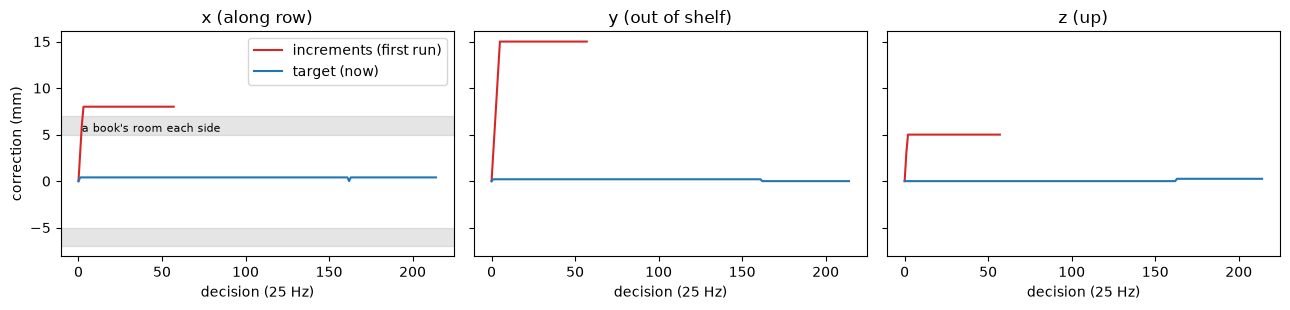

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for i, ax in enumerate(axs):
    for increments, style in ((True, "C3"), (False, "C0")):
        seen = traces[increments]
        ax.plot([1000 * s[1 + i] for s in seen], style,
                label="increments (first run)" if increments else "target (now)")
    ax.set_title(axes[i]); ax.set_xlabel("decision (25 Hz)")
axs[0].set_ylabel("correction (mm)"); axs[0].legend()
axs[0].axhspan(-7, -5, color="grey", alpha=0.2); axs[0].axhspan(5, 7, color="grey", alpha=0.2)
axs[0].text(2, 5.3, "a book's room each side", fontsize=8)
plt.tight_layout()

With increments, the correction climbs a steady 0.3 mm a decision and pins every axis at its bound
(8, 15, 5 mm). Sideways, it passes the book's 5–7 mm of room after ~20 decisions, less than one second of
the slide. The book jams at the slot's entrance. The same action as a target holds the correction at
0.4 / 0.2 / 0 mm, a tenth of the bounds, and the book goes in.

The same comparison on 8 rows, the script alone included. Each episode runs in its own process, 8 at a
time.

In [6]:
SCRIPT = '''
import sys, json, numpy as np
sys.path.insert(0, sys.argv[1])
from bila.control import insert_book as ib
from bila.sim.shelf_scene import ShelfConfig
OLD = np.array([0.008, 0.015, 0.005, np.radians(3), np.radians(3)])
class Steady:
    def __init__(s, a, inc): s.a, s.inc, s.seen = np.asarray(a, float), inc, []
    def decide(s, run, c):
        if c.phase not in ("slide", "push"): return np.zeros(6)
        if s.inc and c.target: c.target, c.lo, c.hi = False, -OLD, OLD
        s.seen.append((c.phase, *run.offset))
        a = np.where(s.a >= 0, s.a * c.hi, -s.a * c.lo) if c.target else s.a
        return np.r_[a, 0.0]
scenario, seed, mode = sys.argv[2], int(sys.argv[3]), sys.argv[4]
model, data, row = ib.make_episode(ShelfConfig(), scenario, np.random.default_rng(seed), ib.DEFAULT_PANDA)
ep = ib.Episode(model, data, row, log=lambda *_: None)
ep.residual = None if mode == "script" else Steady([0.1, 0.1, 0.1, 0, 0], mode == "increments")
try: res = ep.reshelve()
except RuntimeError as e: res = {"success": False, "why": str(e)}
print(json.dumps({"scenario": scenario, "seed": seed, "mode": mode, "success": bool(res.get("success")),
                  "why": res.get("why"), "offset_mm": 1000 * res["offset_m"] if "offset_m" in res else None}))
'''
path = pathlib.Path(tempfile.mkdtemp()) / "steady.py"
path.write_text(SCRIPT)

def one(job):
    out = subprocess.run([sys.executable, str(path), str(ROOT), *map(str, job)], capture_output=True, text=True)
    return json.loads(out.stdout.strip().splitlines()[-1])

jobs = [(s, seed, m) for s in ("clear", "tight") for seed in range(4) for m in ("script", "increments", "target")]
with ThreadPoolExecutor(8) as pool:
    results = list(pool.map(one, jobs))

In [7]:
for m in ("script", "increments", "target"):
    rs = [r for r in results if r["mode"] == m]
    print(f"\n{m}: placed {sum(r['success'] for r in rs)} of {len(rs)}")
    for r in rs:
        how = "placed" if r["success"] else "FAILED"
        detail = r["why"] or (f"spine {r['offset_mm']:+.1f} mm from where it should be" if r["offset_mm"] is not None else "")
        print(f"  {r['scenario']:5} {r['seed']}  {how}  {detail}")


script: placed 8 of 8
  clear 0  placed  spine +0.3 mm from where it should be
  clear 1  placed  spine -0.0 mm from where it should be
  clear 2  placed  spine -0.1 mm from where it should be
  clear 3  placed  spine -0.2 mm from where it should be
  tight 0  placed  spine +0.7 mm from where it should be
  tight 1  placed  spine +0.0 mm from where it should be
  tight 2  placed  spine -0.2 mm from where it should be
  tight 3  placed  spine -0.3 mm from where it should be

increments: placed 3 of 8
  clear 0  FAILED  the book jammed at the slot's entrance
  clear 1  placed  spine +6.3 mm from where it should be
  clear 2  placed  spine +6.6 mm from where it should be
  clear 3  placed  spine +6.6 mm from where it should be
  tight 0  FAILED  the book jammed at the slot's entrance
  tight 1  FAILED  the book jammed at the slot's entrance
  tight 2  FAILED  the book jammed at the slot's entrance
  tight 3  FAILED  spine +91.9 mm from where it should be

target: placed 8 of 8
  clear 0 

What to expect (as run on 2026-11-12):

| mode | placed | how the rest failed |
|---|---|---|
| script alone | 8 / 8 | |
| increments, old bounds | 3 / 8 | 4 jammed at the slot's entrance (clear 0, tight 0–2), 1 left 92 mm proud (tight 3). The 3 that went in were 6–7 mm proud |
| target, current bounds | 8 / 8 | |

Those are the README's two failure modes: "the slide 8 mm sideways and lifted jammed it at the entrance",
and "the push held 15 mm back left the book proud". Most clear rows survive the drift because their gap
is wider (clear 0's isn't). In a tight row, the drift alone failed every time.

## 3. Why PPO couldn't learn its way out

Increments don't only turn a small bias into a big error. They also make learning hard.

- **Exploration is a random walk.** PPO samples each action from a Gaussian around its mean. The
  initial std is `exp(log_std) = exp(−1) ≈ 0.37` (`train_residual.Config`). As increments, independent
  noise adds up like a random walk, so after N decisions the correction's spread is about
  `0.37 × 3 mm × √N`. As a target it is just `0.37 × bound`, and it doesn't grow.

after  25 decisions: increments spread  5.5 mm (28% over 6 mm), target 1.5 mm
after  60 decisions: increments spread  8.5 mm (48% over 6 mm), target 1.5 mm
after 120 decisions: increments spread 12.1 mm (62% over 6 mm), target 1.5 mm


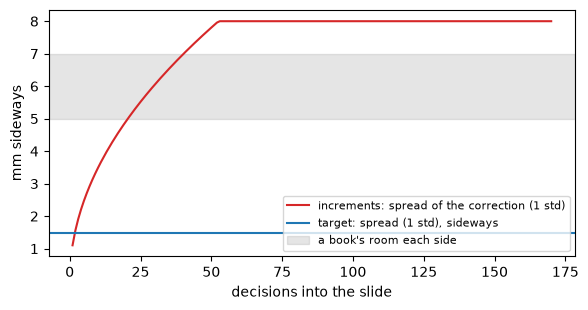

In [8]:
std = np.exp(-1.0)
N = np.arange(1, 171)
walk = 1000 * np.minimum(std * ib.RESIDUAL_STEP * np.sqrt(N), 0.008)        # pinned at the old bound
plt.figure(figsize=(6, 3.2))
plt.plot(N, walk, "C3", label="increments: spread of the correction (1 std)")
plt.axhline(1000 * std * ib.SLIDE_HI[0], color="C0", label="target: spread (1 std), sideways")
plt.axhspan(5, 7, color="grey", alpha=0.2, label="a book's room each side")
plt.xlabel("decisions into the slide"); plt.ylabel("mm sideways"); plt.legend(fontsize=8); plt.tight_layout()
from math import erf, sqrt
for n in (25, 60, 120):
    s = 1000 * std * ib.RESIDUAL_STEP * np.sqrt(n)
    off = 2 * (1 - 0.5 * (1 + erf(6 / s / sqrt(2))))                        # P(|correction| > 6 mm)
    print(f"after {n:3d} decisions: increments spread {s:4.1f} mm ({100*off:.0f}% over 6 mm), "
          f"target {1000*std*ib.SLIDE_HI[0]:.1f} mm")

With noise alone, the share of rollouts more than 6 mm off sideways is about 28% after 25 decisions (1 s),
48% after 60 and 62% after 120 (a normal spread with the std above). So many exploratory slides jam or come out proud whatever the mean is. The learning signal is
dominated by those failures, not by the small corrections a residual exists to learn.

- **The reward charges for steps, not for position.** `ACTION_PENALTY` (`gap_env.py`) costs
  `0.1 × |increment / step|²` per decision. A steady increment of 0.1 costs 0.001 a decision, which is
  nothing next to `PROGRESS_REWARD` (1 per cm). Once the correction has drifted, *staying* drifted is free.
  Only the terminal `MISSED_PENALTY` / `FAILURE_PENALTY` (5 / 10) push back, and they arrive hundreds of
  decisions after the drift that caused them (`gamma = 0.99`, a ~4 s horizon).
- **The actor sees its offset, but late.** The observation includes the correction so far, so in
  principle the policy could steer it back to 0. In practice it has to learn that from the rare rollouts
  that weren't already pinned at a bound.

Target actions fix all three: a mean of 0 is the script, noise doesn't accumulate, and the policy's output
*is* where the hand is relative to the script.

## 4. Cause 2: what it trained on

The residual's first pools saw the row through `NoisyPerception` (`NoisyEyes`: the truth plus the camera's
measured errors, no rendering) because rendering is slow. The branch's `eval_reshelve.py` then ran the
script alone, no residual, on clear and tight seeds 0–99 (200 rows) with each perception (README,
"Training on what the robot sees"):

| perception | placed | missed after inserting | gave up before inserting | how insertions failed |
|---|---|---|---|---|
| ground truth | 198 | 0 of 198 | 2 | |
| camera, learned masks | 163 | 22 of 185 | 15 | 15 left proud, 7 jammed |
| `noisy-learned` (its imitation) | 158 | 21 of 179 | 21 | **12 jammed**, 9 left proud |
| camera, the simulation's masks | 162 | 25 of 187 | 13 | 16 left proud, 8 jammed |
| `noisy` | 164 | 19 of 183 | 17 | **12 jammed**, 7 left proud |

The noise models fail about as *often* as the camera, but in other *ways*:

- **The camera mostly leaves the book proud; the noise models mostly jam it.** A policy trained on them
  learns to free jams, which the robot's own failures mostly aren't.
- **The noise models also give up on rows the camera handles** ("the fingers can't reach a neighbour with
  room behind it"). Those are rows where PPO never gets to act.
- **More noise doesn't help.** `noisy` at 1.5× and 2× placed 138 and 123: it only adds failures the camera
  doesn't make.

Part of why they differ is in `docs/calibration-and-insertion.md`. The camera's biggest error is the
hand-eye calibration, a shift that is fixed within an episode and differs by view. `NoisyPerception`
draws independent errors per book, which behave differently in the gap estimate. The shelf fiducials now
remove most of the camera's sideways shift, so the camera's failure mix has changed again since this table
was made. Rerun `eval_reshelve.py` (below) before building new pools.

## 5. What was changed, and what isn't known yet

Changed on the branch, and now merged:

- insertion actions are targets, inside tight bounds (`SLIDE_LO/HI`, `PUSH_LO/HI`; sections 1–3);
- the insertion residual trains on the rendered camera with learned masks, not on a noise model
  (`--perception camera`; section 4). A pool records how it was made, and `GapEnv` refuses one made
  differently.

Not known yet: **no policy trained with these fixes has been evaluated.** The README calls the 16-layout
debug run "a diagnostic run, not an established convergence budget". Those pools also had almost no
insertion misses to learn from: with the script at 0 misses of 198 under ground truth, a residual can only
help where perception is wrong.

To get the answer:

```bash
# how the script alone fails now, with the fiducial correction (the camera's failure mix has changed)
MUJOCO_GL=egl uv run --group rl python -m bila.control.eval_reshelve run --perception camera \
    --segmenter bila_weights/segmenter/segmenter.pt --out results/camera-learned.jsonl
# pools from the camera with learned masks, then train only the insertion
for scenario in clear tight; do
  uv run --group rl python -m bila.rl.gap_env pool --scenario "$scenario" --seeds 100 --first-seed 10000 \
    --perception camera --segmenter bila_weights/segmenter/segmenter.pt --name "${scenario}_camera" --workers 10
  uv run --group rl python -m bila.rl.gap_env pool --scenario "$scenario" --seeds 50 --first-seed 20000 \
    --perception camera --segmenter bila_weights/segmenter/segmenter.pt --name "${scenario}_camera_val" --workers 10
done
uv run --group rl python -m bila.rl.train_residual --name insertion_camera --scenarios clear tight \
  --train-suffix _camera --val-suffix _camera_val --control-phases slide push --no-learn-stop \
  --perception camera --segmenter bila_weights/segmenter/segmenter.pt --workers 10
```

`runs/insertion_camera/val_*.json` then gives `val_recovered`, `val_lost` and `val_success_delta`: the
rows the policy saved and lost against the script, on identical cases. That is the number this notebook
can't give yet.